# Internet Aesthetics-- Text Analysis

1. Tags (motifs + colours + values) --> TF-IDF → topics + clusters
2. Overview text → TF-IDF → topics + clusters
3. Unexpected neighbours-- close aesthetics the wiki doesn't link
4. Can the text predict the era? — `MultinomialNB`
5. Map for the final piece-- t-SNE --> JSON

## Setup

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/text_utils.py" -O text_utils.py

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

from data_utils import display_confusion_matrix, distance_score, balance_score, silhouette_score
from text_utils import get_top_words

In [3]:
# fillna("") --> empty text instead of NaN
aes_df = pd.read_csv("data/clean/aesthetics_clean.csv").fillna("")

print(aes_df.shape)
display(aes_df.head())

(1022, 10)


/tmp/ipykernel_11769/2982892332.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  aes_df = pd.read_csv("data/clean/aesthetics_clean.csv").fillna("")


,title,decade,decade_source,era,motifs,colours,values,tags_text,overview,overview_words
0,Mallsoft,2010.0,hugging face,Tumblr,"shopping malls (empty and full), mall food, ma...","pink, teal, mint green, purple, black, white, ...","shop till you drop, exploration",shopping malls (empty and full) mall food ma...,Mallsoft's approach to shopping malls is based...,26
1,Femme Fatale,1940.0,hugging face,pre-internet,"mystery, intelligence, beauty, seduction, power","red, black, dark green, dark blue, metallic tones","enticement, scheming, heartlessness, lust",mystery intelligence beauty seduction powe...,"The ""Femme Fatale"" trope is a collection of im...",27
2,Indicolite,2020.0,hugging face,TikTok,"diamonds, water, clouds, vintage statues","blue, indigo, cyan, white, grey",,diamonds water clouds vintage statues blue ...,The 'Indicolite' aesthetic is based on the aes...,49
3,Kingcore,,none,unknown,"control, leadership, war, crowns, royal lifest...","gold, royal blue, black, white, purple, red","power, money, hedonism, conquest, status, duty...",control leadership war crowns royal lifest...,The 'Kingcore' aesthetic is based on the theme...,34
4,Onii Kei,1990.0,zenodo,Old Web,,,,,Japanese fashion is often referred to as 'Onii...,60


---
# 1. Tags

Only aesthetics that have tags. `min_df=5`: a word must appear in at least 5 aesthetics. `max_df=0.5`: drop words used by more than half.

In [4]:
tag_df = aes_df[aes_df["tags_text"] != ""].reset_index(drop=True)

tag_vec = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5)
tag_vct = tag_vec.fit_transform(tag_df["tags_text"])

tag_vocab = tag_vec.get_feature_names_out()
print(tag_vct.shape)
print(tag_vocab[:50])

(943, 615)
['2000s' '3d' '80s' 'abandoned' 'abstract' 'academic' 'accents'
 'acceptance' 'accessories' 'activism' 'activities' 'adventure'
 'aesthetic' 'aesthetics' 'alcohol' 'alienation' 'ambition' 'american'
 'ancient' 'androgyny' 'angels' 'animal' 'animals' 'animation' 'anime'
 'anti' 'appearance' 'appreciation' 'architecture' 'areas' 'art'
 'artistic' 'arts' 'attire' 'attitude' 'auroras' 'authenticity'
 'authoritarianism' 'awareness' 'baby' 'bad' 'balance' 'band' 'based'
 'bats' 'beach' 'beaches' 'beauty' 'beige' 'big']


### Topics (SVD)

top words of each SVD component.

In [5]:
tag_svd = TruncatedSVD(n_components=8, random_state=1010)
tag_svd.fit(tag_vct)

tag_topics = get_top_words(tag_svd.components_, tag_vocab, n_words=8)
for i in range(len(tag_topics)):
  print("topic", i, tag_topics[i])

topic 0 ['black', 'white', 'red', 'blue', 'green', 'grey', 'pink', 'brown']
topic 1 ['colors', 'bright', 'neon', 'pink', 'pastels', 'pastel', 'culture', 'rainbow']
topic 2 ['brown', 'dark', 'grey', 'tones', 'green', 'nature', 'beige', 'earth']
topic 3 ['black', 'grey', 'white', 'colors', 'bright', 'shock', 'value', 'neon']
topic 4 ['pink', 'white', 'beige', 'self', 'brown', 'love', 'pastel', 'femininity']
topic 5 ['neon', 'grey', 'green', 'blue', 'purple', 'black', 'colors', 'rainbow']
topic 6 ['dark', 'purple', 'pink', 'neon', 'mystery', 'horror', 'colours', 'nature']
topic 7 ['gold', 'silver', 'neon', 'tones', 'black', 'colors', 'purple', 'brown']


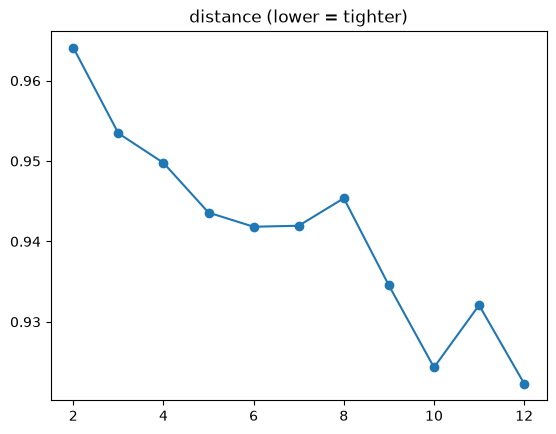

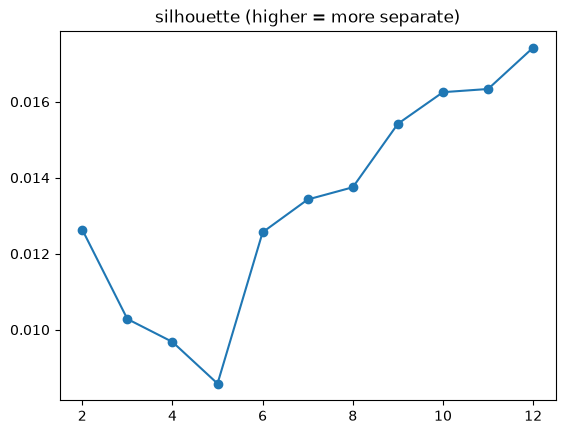

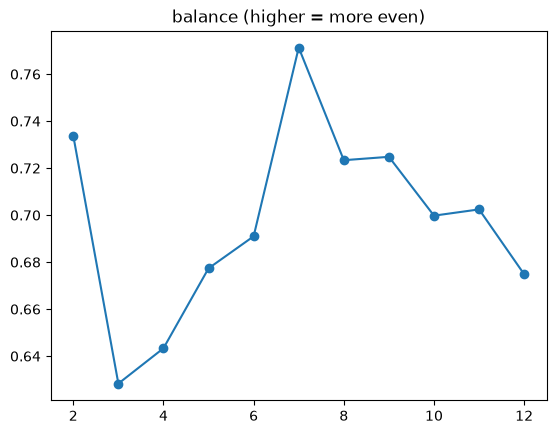

In [6]:
tag_dense = tag_vct.toarray()

ks = list(range(2, 13))
dist_scores = []
sil_scores = []
bal_scores = []

for k in ks:
  pred = KMeans(n_clusters=k, random_state=1010).fit_predict(tag_vct)
  dist_scores.append(distance_score(tag_dense, pred))
  sil_scores.append(silhouette_score(tag_dense, pred))
  bal_scores.append(balance_score(pred))

plt.plot(ks, dist_scores, marker="o")
plt.title("distance (lower = tighter)")
plt.show()
plt.plot(ks, sil_scores, marker="o")
plt.title("silhouette (higher = more separate)")
plt.show()
plt.plot(ks, bal_scores, marker="o")
plt.title("balance (higher = more even)")
plt.show()

`TAG_K` from the plots. Cluster centers are "average aesthetics", and `get_top_words()` shows their top words.

In [7]:
TAG_K = 8

tag_km = KMeans(n_clusters=TAG_K, random_state=1010)
tag_df["tag_cluster"] = tag_km.fit_predict(tag_vct)

tag_cluster_words = get_top_words(tag_km.cluster_centers_, tag_vocab, n_words=8)

for c in range(TAG_K):
  in_c = tag_df[tag_df["tag_cluster"] == c]
  print("CLUSTER", c, "-", len(in_c), "aesthetics")
  print("  words:", tag_cluster_words[c])
  print("  e.g.:", list(in_c["title"].head(8)))
  print("  eras:", list(in_c["era"].value_counts().index[:3]))
  print()

CLUSTER 0 - 262 aesthetics
  words: ['music', 'color', 'self', 'love', 'fashion', 'low', 'black', 'pink']
  e.g.: ['Hands Up', 'Cheiron Crush', 'Pin-up', 'The Box 96', 'Electronic Body Music', 'Major League Gaming', 'Cyberpunk', 'Delicate Sweet']
  eras: ['unknown', 'pre-internet', 'Web 2.0']

CLUSTER 1 - 29 aesthetics
  words: ['shock', 'value', 'national', 'leather', 'red', 'celtic', 'imagery', 'black']
  e.g.: ['Interceltic', 'Neue Slowenische Kunst', 'Lottie Clone', 'Mexican Muralism', 'Rockstar GF', 'Raggare', 'Kiwiana', 'Shiny Suit 97']
  eras: ['pre-internet', 'unknown', 'Tumblr']

CLUSTER 2 - 56 aesthetics
  words: ['horror', 'blues', 'greens', 'black', 'white', 'darkness', 'yellows', 'reds']
  e.g.: ['Kawaii', 'Whimsigothic', 'Avant Basic', 'Ostalgie', 'Trad Goth', 'Poolcore', 'Kimoicore', 'Cybermorphism']
  eras: ['unknown', 'Tumblr', 'TikTok']

CLUSTER 3 - 106 aesthetics
  words: ['colors', 'bright', 'neon', 'pastels', 'pink', 'black', 'characters', 'white']
  e.g.: ['New Ra

---
# 2. Overview Text

In [8]:
lang_vec = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5)
lang_vct = lang_vec.fit_transform(aes_df["overview"])

lang_vocab = lang_vec.get_feature_names_out()
print(lang_vct.shape)

(1022, 1089)


In [9]:
lang_svd = TruncatedSVD(n_components=20, random_state=1010)
lang_svd_feats = lang_svd.fit_transform(lang_vct)

lang_topics = get_top_words(lang_svd.components_[:8], lang_vocab, n_words=8)
for i in range(len(lang_topics)):
  print("topic", i, lang_topics[i])

topic 0 ['aesthetic', 'based', 'aesthetics', 'combination', 'elements', 'style', 'despite', 'themes']
topic 1 ['despite', 'lack', 'fact', 'clear', 'people', 'movement', 'emergence', 'able']
topic 2 ['aesthetics', 'combination', 'based', 'despite', 'clear', 'lack', 'people', 'fact']
topic 3 ['style', 'aesthetics', 'combination', 'design', 'influenced', 'interior', 'fashion', 'movement']
topic 4 ['art', 'movement', 'artists', 'aesthetics', 'states', 'united', 'artistic', 'focus']
topic 5 ['combination', 'elements', 'characterized', 'movement', 'lack', 'visual', 'artistic', 'art']
topic 6 ['music', 'aesthetics', 'genre', 'focus', 'culture', 'academia', 'strong', 'lack']
topic 7 ['characterized', 'focus', 'academia', 'lack', 'style', 'clear', 'art', 'blend']


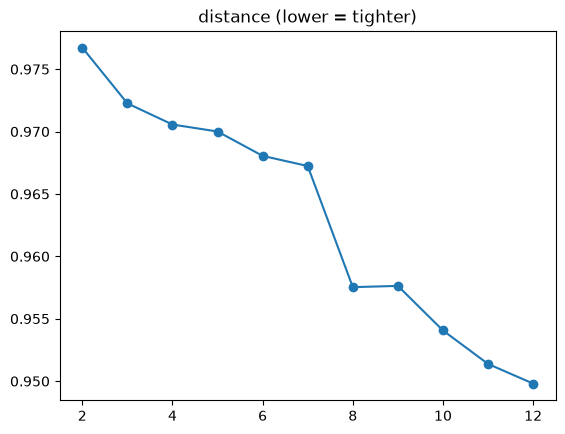

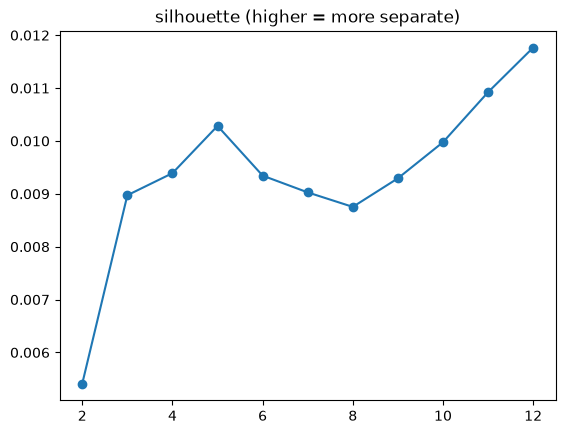

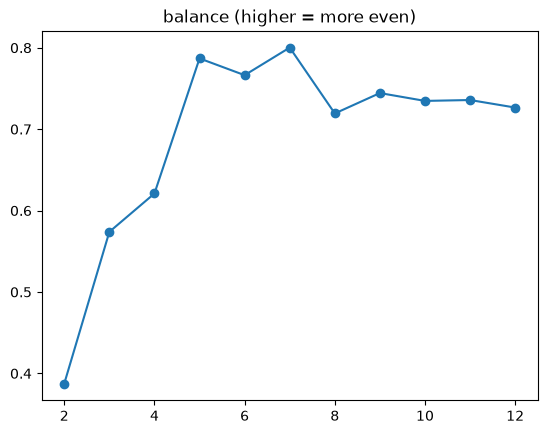

In [10]:
lang_dense = lang_vct.toarray()

dist_scores = []
sil_scores = []
bal_scores = []

for k in ks:
  pred = KMeans(n_clusters=k, random_state=1010).fit_predict(lang_vct)
  dist_scores.append(distance_score(lang_dense, pred))
  sil_scores.append(silhouette_score(lang_dense, pred))
  bal_scores.append(balance_score(pred))

plt.plot(ks, dist_scores, marker="o")
plt.title("distance (lower = tighter)")
plt.show()
plt.plot(ks, sil_scores, marker="o")
plt.title("silhouette (higher = more separate)")
plt.show()
plt.plot(ks, bal_scores, marker="o")
plt.title("balance (higher = more even)")
plt.show()

In [11]:
LANG_K = 8

lang_km = KMeans(n_clusters=LANG_K, random_state=1010)
aes_df["lang_cluster"] = lang_km.fit_predict(lang_vct)

lang_cluster_words = get_top_words(lang_km.cluster_centers_, lang_vocab, n_words=8)

for c in range(LANG_K):
  in_c = aes_df[aes_df["lang_cluster"] == c]
  print("CLUSTER", c, "-", len(in_c), "aesthetics")
  print("  words:", lang_cluster_words[c])
  print("  e.g.:", list(in_c["title"].head(8)))
  print("  eras:", list(in_c["era"].value_counts().index[:3]))
  print()

CLUSTER 0 - 157 aesthetics
  words: ['aesthetic', 'based', 'themes', 'including', 'key', 'includes', 'focus', 'range']
  e.g.: ['Indicolite', 'Kingcore', 'Acidwave', 'Avant Basic', '2020 Alt', 'Craftcore', 'Yakuza', 'Athlete']
  eras: ['unknown', 'pre-internet', 'Tumblr']

CLUSTER 1 - 128 aesthetics
  words: ['aesthetics', 'combination', 'based', 'academia', 'aesthetic', 'themes', 'focus', 'characterized']
  e.g.: ['Yandere', 'List of Aesthetics', 'Gamercore', 'Stellar Scholar', 'Purism', 'Nuclear', 'Post-Rock', 'Earthy Black Girl']
  eras: ['unknown', 'pre-internet', 'Tumblr']

CLUSTER 2 - 31 aesthetics
  words: ['world', 'aesthetic', 'explore', 'desire', 'based', 'war', 'cyberpunk', 'ii']
  e.g.: ['Unicorncore', 'Cyberpunk', 'Urban Fantasy', 'Bankara', 'Surrealism', 'Bosozoku', 'Cyberprep', 'Adventurecore']
  eras: ['pre-internet', 'unknown', 'Tumblr']

CLUSTER 3 - 37 aesthetics
  words: ['inspiration', 'draws', 'art', 'style', 'aesthetic', 'japanese', 'victorian', 'sources']
  e.g.:

---
# 3. Unexpected Neighbours

For each favourite: the 5 closest aesthetics by overview text (Euclidean distance on the 20 SVD features, same as `dist()`), and whether the wiki links them.

In [13]:
edges_df = pd.read_csv("data/raw/wiki_ecosystem_edges.csv")

linked = set()
for a, b in zip(edges_df["aesthetic"], edges_df["related"]):
  linked.add((a, b))
  linked.add((b, a))

names = list(aes_df["title"])

In [14]:
favorites = ["Vaporwave", "Frutiger Aero", "Webcore", "Weirdcore", "Dreamcore", "Seapunk"]

for fav in favorites:
  i = names.index(fav)

  dists = []
  for j in range(len(names)):
    s = 0
    for a, b in zip(lang_svd_feats[i], lang_svd_feats[j]):
      s += (a - b) ** 2
    dists.append(s ** 0.5)

  closest = pd.Series(dists).sort_values().index[1:6]   # [0] is itself

  neighbours = []
  for j in closest:
    if (fav, names[j]) in linked:
      neighbours.append(names[j])
    else:
      neighbours.append(names[j] + " (NOT linked)")

  print(fav, "->", neighbours)

Vaporwave -> ['Grunge (NOT linked)', 'Wehraboo (NOT linked)', 'Rave (NOT linked)', 'Y2K Futurism', 'Waif (NOT linked)']
Frutiger Aero -> ['Pokemón (NOT linked)', 'New Beat (NOT linked)', 'Cryptidcore (NOT linked)', 'Raggare (NOT linked)', 'Club Kids (NOT linked)']
Webcore -> ['Lolicore (NOT linked)', 'Basque Radical Rock (NOT linked)', 'Krushclub (NOT linked)', 'Hyperpop (NOT linked)', 'Larpercore (NOT linked)']
Weirdcore -> ['Emo Rap (NOT linked)', 'Motomami (NOT linked)', 'PMC Ryodan (NOT linked)', 'Pride flags (NOT linked)', 'Incel (NOT linked)']
Dreamcore -> ['Hauntology (NOT linked)', 'Thriftcore (NOT linked)', 'Lowbrow (NOT linked)', 'Picniccore (NOT linked)', 'Purism (NOT linked)']
Seapunk -> ['90s Cool (NOT linked)', 'Breakcore (NOT linked)', 'Kandi Raver (NOT linked)', 'Opium (NOT linked)', 'Bubblegum Dance (NOT linked)']


---
# 4. Can the Text Predict the Era?

Like the movie-review classifier. Drop `unknown`, and take the same number from each era so the model can't just guess the biggest one.

In [15]:
era_df = aes_df[aes_df["era"] != "unknown"]
print(era_df["era"].value_counts())

min_count = era_df["era"].value_counts().min()

parts = []
for era in era_df["era"].unique():
  parts.append(era_df[era_df["era"] == era].sample(n=min_count, random_state=1010))

era_balanced_df = pd.concat(parts)
print("balanced:", min_count, "per era")

era
pre-internet    283
Tumblr          148
Web 2.0         101
Old Web          82
TikTok           81
Name: count, dtype: int64
balanced: 81 per era


train accuracy: 0.917
test accuracy: 0.321
random guess: 0.2


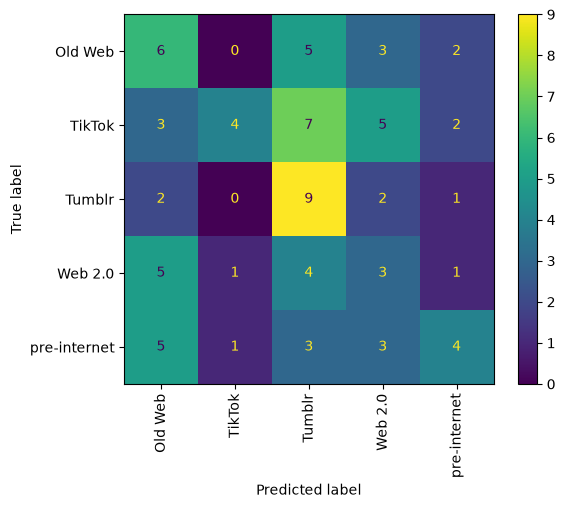

In [16]:
era_train_df, era_test_df = train_test_split(era_balanced_df, test_size=0.2, random_state=1010)

era_vec = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.5)
era_train_vct = era_vec.fit_transform(era_train_df["overview"])
era_test_vct = era_vec.transform(era_test_df["overview"])

era_model = MultinomialNB()
era_model.fit(era_train_vct, era_train_df["era"])

train_preds = era_model.predict(era_train_vct)
test_preds = era_model.predict(era_test_vct)

print("train accuracy:", round(accuracy_score(era_train_df["era"], train_preds), 3))
print("test accuracy:", round(accuracy_score(era_test_df["era"], test_preds), 3))
print("random guess:", round(1 / era_balanced_df["era"].nunique(), 3))

era_labels = sorted(era_balanced_df["era"].unique())
display_confusion_matrix(era_test_df["era"], test_preds, era_labels)

In [17]:
era_vocab = era_vec.get_feature_names_out()

for era in era_labels:
  era_text = " ".join(era_balanced_df[era_balanced_df["era"] == era]["overview"])
  print(era, get_top_words(era_vec.transform([era_text]), era_vocab, n_words=10))

Old Web ['despite', '1990s', 'aesthetic', 'music', 'style', 'british', 'late', 'popular', 'influenced', 'elements']
TikTok ['aesthetic', 'based', 'academia', 'aesthetics', 'trend', 'pursuit', 'focus', 'blend', 'girl', 'elements']
Tumblr ['aesthetic', 'based', 'aesthetics', 'themes', 'combination', 'nature', 'academia', 'elements', 'colors', 'focus']
Web 2.0 ['style', 'themes', 'aesthetic', '2000s', 'despite', 'elements', 'aesthetics', 'combination', 'punk', 'music']
pre-internet ['extreme', 'girl', 'style', 'art', 'aesthetics', 'despite', 'social', 'focus', 'culture', 'movement']


---
# 5. Map

t-SNE on the 20 SVD features → 2D, coloured by cluster and by era.

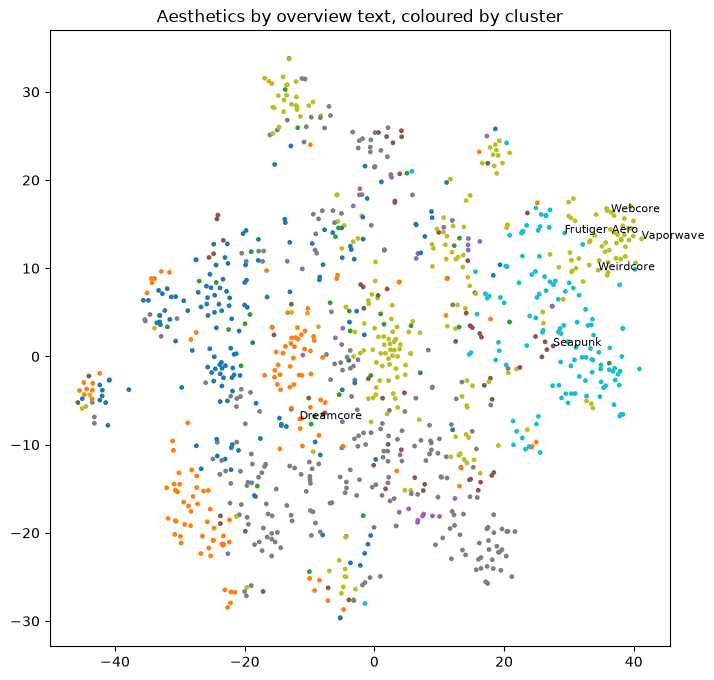

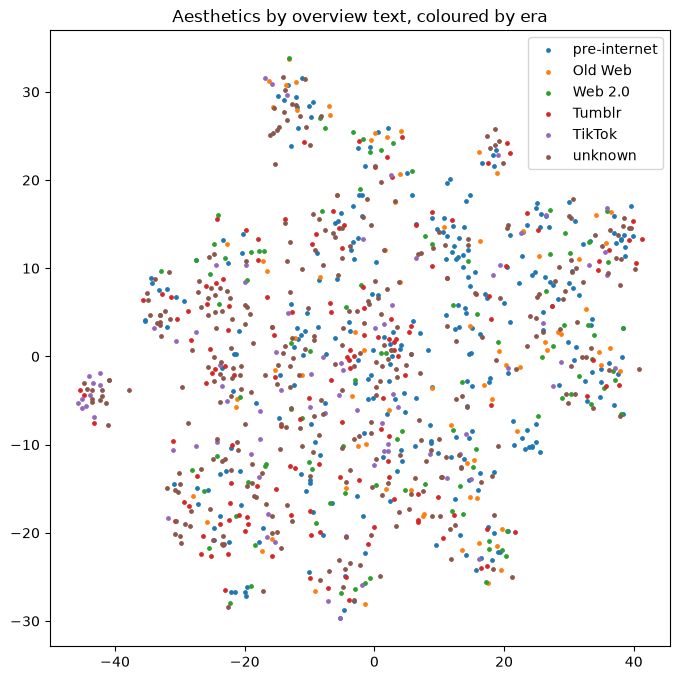

In [18]:
tsne = TSNE(n_components=2, random_state=1010).set_output(transform="pandas")
map_df = tsne.fit_transform(lang_svd_feats)

aes_df["map_x"] = map_df["tsne0"].values
aes_df["map_y"] = map_df["tsne1"].values

plt.figure(figsize=(8, 8))
plt.scatter(aes_df["map_x"], aes_df["map_y"], c=aes_df["lang_cluster"], cmap="tab10", s=6)
for fav in favorites:
  i = names.index(fav)
  plt.annotate(fav, (aes_df["map_x"][i], aes_df["map_y"][i]), fontsize=8)
plt.title("Aesthetics by overview text, coloured by cluster")
plt.show()

era_order = ["pre-internet", "Old Web", "Web 2.0", "Tumblr", "TikTok", "unknown"]

plt.figure(figsize=(8, 8))
for era in era_order:
  in_era = aes_df[aes_df["era"] == era]
  plt.scatter(in_era["map_x"], in_era["map_y"], s=6, label=era)
plt.legend()
plt.title("Aesthetics by overview text, coloured by era")
plt.show()

In [19]:
!mkdir -p output

map_cols = ["title", "era", "decade", "map_x", "map_y", "lang_cluster", "motifs", "colours", "values", "overview"]
aes_df[map_cols].to_json("output/aesthetics_map.json", orient="records", indent=1)

print(aes_df[map_cols].shape)

(1022, 10)
